In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
import numpy as np
import scanpy as sc
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import re


In [2]:
adata_RRmap = sc.read_h5ad('../data/RREAE_5k_raw.h5ad')
adata_EAE5K = sc.read_h5ad('../data/eae_5k_raw.h5ad')
adata_mtDSB = sc.read_h5ad('../data/mtDNA_DSB_5k_raw.h5ad')

In [3]:
adata_EAE5K.obs["sample_extracted"] = adata_EAE5K.obs["run"].str.extract(r"__(G\d+_L\d+)__")
adata_RRmap.obs["sample_extracted"] = adata_RRmap.obs["sample"].str.extract(r"__(S\d+-[A-Za-z]+\d+)__")
adata_mtDSB.obs["sample_extracted"] = adata_mtDSB.obs["run"].str.extract(r"__(RB\d+)__")

In [4]:
adata_mtDSB.obs_names_make_unique()
adata_RRmap.obs_names_make_unique()
adata_EAE5K.obs_names_make_unique()

In [5]:
adata_mtDSB.obs['project'] = 'mtDSB'
adata_RRmap.obs['project'] = 'RREAE'
adata_EAE5K.obs['project'] = 'Chronic EAE'
ad = sc.concat(
    {
        "RRmap": adata_RRmap,
        "EAE5K": adata_EAE5K,
        "mtDSB": adata_mtDSB,
    },
    label="dataset",       # new column in .obs
    keys=None,             # use dict keys above
    index_unique="-",      # make indices unique: barcode-dataset
    join="outer",          # keep all genes (union)
    merge="same"           # only merge .obs/.var columns that are identical
)

In [6]:
ad.write('../data/integrated_2.h5ad')

In [7]:
# 2) (Optional) light filtering
sc.pp.filter_cells(ad, min_counts=40)      # tune if needed
sc.pp.filter_genes(ad, min_cells=5)

# 3) Normalize & log1p (sparse-friendly in modern Scanpy)
sc.pp.normalize_total(ad, target_sum=1e4)
sc.pp.log1p(ad)


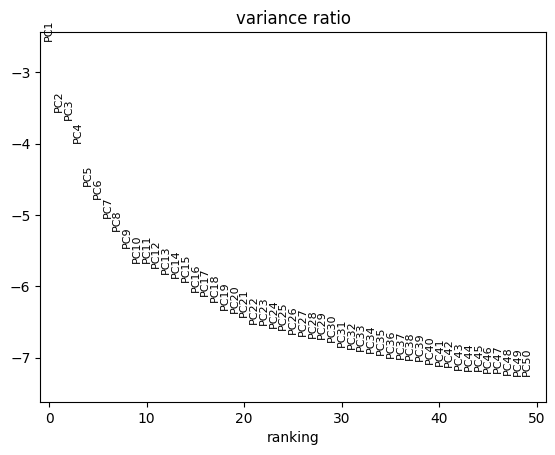

In [8]:
plt.rcdefaults()
sc.tl.pca(ad)
sc.pl.pca_variance_ratio(ad, n_pcs=50, log=True)
sc.pp.neighbors(ad, n_neighbors=15, n_pcs=30)

In [9]:
sc.tl.umap(ad, min_dist=0.1)

IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out


Skipping 0.5: leiden_0.5 already exists.


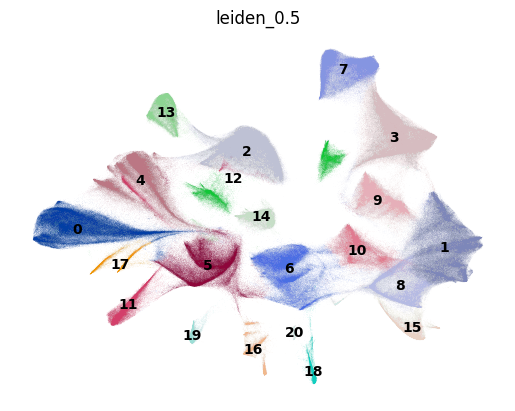

Clustering at resolution 1...
Done.


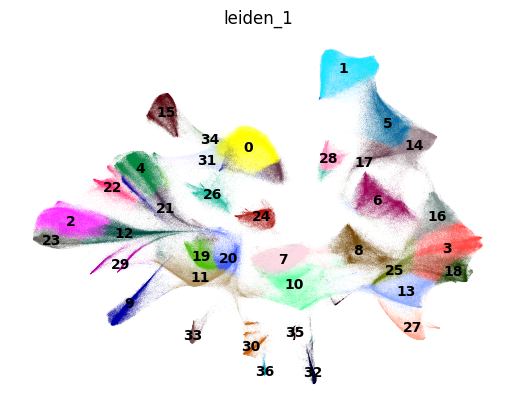

Clustering at resolution 1.5...
Done.


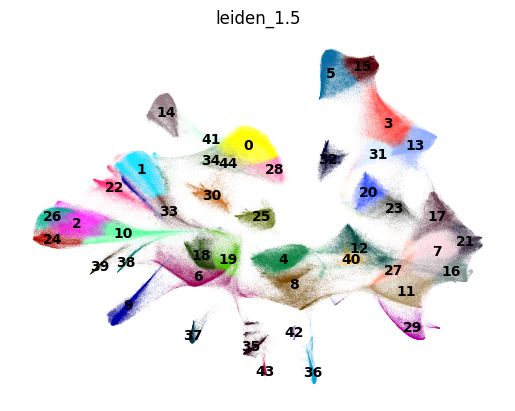

Clustering at resolution 2...
Done.


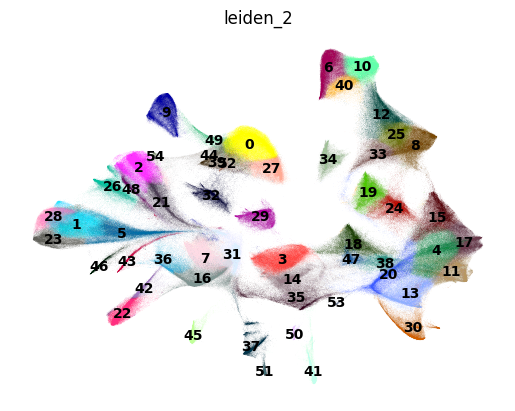

In [21]:
resolutions = [0.5, 1,1.5, 2]

for resolution in resolutions:
    key = f'leiden_{resolution}'

    if key in ad.obs.columns:
        print(f"Skipping {resolution}: {key} already exists.")
    else:
        print(f"Clustering at resolution {resolution}...")
        sc.tl.leiden(ad, resolution=resolution, key_added=key)
        print("Done.")

    # plot UMAP
    sc.pl.umap(ad, color=key, legend_loc='on data', frameon=False)

In [34]:
ad

AnnData object with n_obs × n_vars = 1703389 × 5101
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'run', 'sample', 'grid_label', 'sample_extracted', 'project', 'dataset', 'n_counts', 'leiden_0.5', 'leiden_1', 'leiden_1.5', 'leiden_2'
    var: 'n_cells'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_0.5_colors', 'leiden_1_colors', 'leiden_1.5_colors', 'leiden_2_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

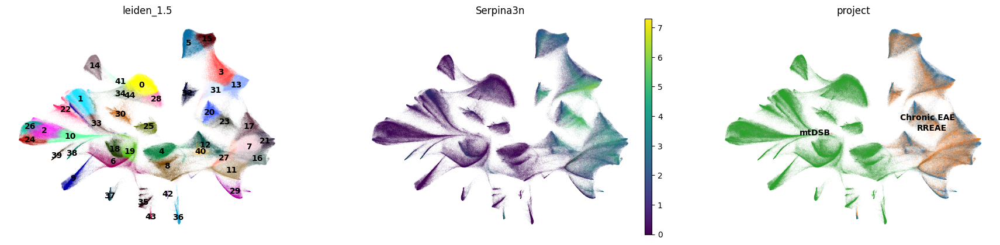

In [36]:
sc.pl.umap(ad, color = ['leiden_1.5','Serpina3n', 'project'], legend_loc='on data', frameon=False)

In [32]:
ad.write('../data/integrated_clustered_full.h5ad')

In [23]:
spatial = np.array(ad.obs[['x_centroid','y_centroid']])
ad.obsm['spatial'] = spatial

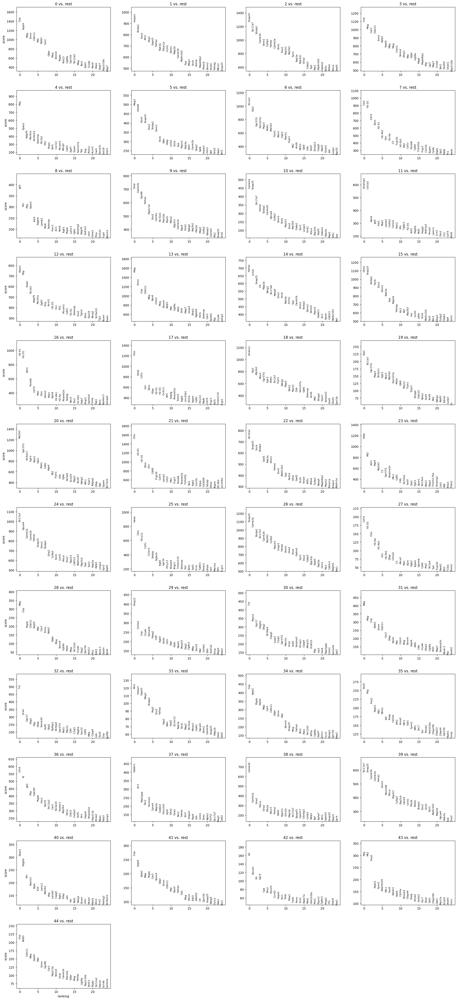

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,Cnp,1385.842285,5.614027,0.0,0.0
1,0,Sept4,1212.604858,5.474541,0.0,0.0
2,0,Mbp,1049.836304,3.714124,0.0,0.0
3,0,Ermn,1029.459106,5.828598,0.0,0.0
4,0,Cldn11,983.230408,6.102320,0.0,0.0


In [25]:
# --- Find marker genes per cluster ---
sc.tl.rank_genes_groups(ad, groupby="leiden_1.5", method="t-test")
sc.pl.rank_genes_groups(ad, n_genes=25, sharey=False)

# get a tidy table of top markers
markers = sc.get.rank_genes_groups_df(ad, group=None)
markers.head()

In [26]:
marker_genes = pd.DataFrame({
    group: ad.uns['rank_genes_groups']['names'][group][:20]
    for group in ad.uns['rank_genes_groups']['names'].dtype.names
})


In [27]:
for col in marker_genes.columns: 
    print(col)
    genes = marker_genes[col].tolist()
    print(" ".join(genes))
    print(' ')

0
Cnp Sept4 Mbp Ermn Cldn11 Mal Aplp1 Car2 Qdpr Mog Stmn4 Ptgds Rnf13 Ugt8a Gprc5b Slc12a2 Mag Bin1 Edil3 Cryab
 
1
Impact Stxbp1 Eno2 Ahi1 Peg3 Gap43 Ywhaz Rab3a Prkar1a Uchl1 Dnm1 Map1b Camk2b Atp6v1b2 Syp Meg3 Sncb Rnf14 Mapk8ip2 Prkacb
 
2
Snap25 Slc17a7 Stxbp1 Camk2b Dnm1 Cyfip2 Ywhaz Camk2a Sncb Eno2 Ppp3r1 Atp2b2 Syn1 Rab3a Ppp3cb Gria2 Cabp1 Syp Pak1 Atp6v1b2
 
3
Cnp Mag Car2 Cldn11 Ermn Aplp1 Sept4 Mbp Mog Cntn2 Stmn4 Efnb3 Mal Qdpr Ugt8a Mapt Mapk8ip1 Pllp Lgi3 Map7
 
4
Pltp Epas1 Adgrf5 Abcb1a Slc9a3r2 Selenop Slc2a1 Flt1 Podxl Itih5 Cxcl12 Pecam1 Abcg2 Cdh5 Egfl7 Esam Fam107a Tek Eng Prom1
 
5
Meg3 Hoxb8 Glra1 Snap25 Eno2 Stxbp1 Dnm1 Sncb Ndn Gfap Uchl1 Sv2a Syp Ptprn2 Rab3a Ebf3 Camk2b Disp2 Sptb Impact
 
6
Slc1a3 Gja1 Gpr37l1 Fam107a Plpp3 Aldoc Atp1b2 Ttyh1 Ntsr2 Fgfr3 Ptprz1 S1pr1 Mt2 Acsl6 Ntrk2 Gjb6 Ckb Sox9 Slc6a11 Cspg5
 
7
Ctss H2-D1 Cd74 B2m H2-K1 H2-Ab1 Grn H2-Aa C3 Fcgr2b H2-Eb1 Msn Csf1r Psmb8 Cd68 Tnfrsf1b Fcgr3 Cxcl16 Itgam Cybb
 
8
Igf2 Vtn Pltp Epas1 Itih5 

In [28]:
ad.obs

,x_centroid,y_centroid,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,...,sample,grid_label,sample_extracted,project,dataset,n_counts,leiden_0.5,leiden_1,leiden_1.5,leiden_2
cell_id,,,,,,,,,,,,,,,,,,,,,
aaadgfgj-1-RRmap,181.586823,1630.103394,474,0,0,0,3,0,477,48.317189,...,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,474.0,7,1,5,6
aaaeckib-1-RRmap,212.154877,1685.950928,882,0,0,0,1,0,883,46.194845,...,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,882.0,7,1,5,6
aaaemkgl-1-RRmap,235.259537,1613.899048,1561,0,0,1,6,1,1569,112.800317,...,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,1561.0,7,1,5,10
aaagfkdi-1-RRmap,213.706497,1525.154907,1403,0,1,0,3,1,1408,71.708128,...,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,1403.0,7,1,5,6
aaagghkg-1-RRmap,196.850647,1526.920288,785,0,0,0,1,0,786,33.235001,...,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,785.0,7,1,5,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
oifndkbo-1-mtDSB,2379.717529,4785.681152,419,0,0,0,0,0,419,42.221095,...,NaN,NaN,RB4676,mtDSB,mtDSB,419.0,13,19,18,7
oifolalk-1-mtDSB,2281.881104,4803.725098,219,0,0,0,0,0,219,36.170158,...,NaN,NaN,RB4676,mtDSB,mtDSB,219.0,4,21,33,21
oifphdni-1-mtDSB,2343.403564,4830.252441,76,0,0,0,0,0,76,14.946719,...,NaN,NaN,RB4676,mtDSB,mtDSB,76.0,5,20,19,31


RB4282


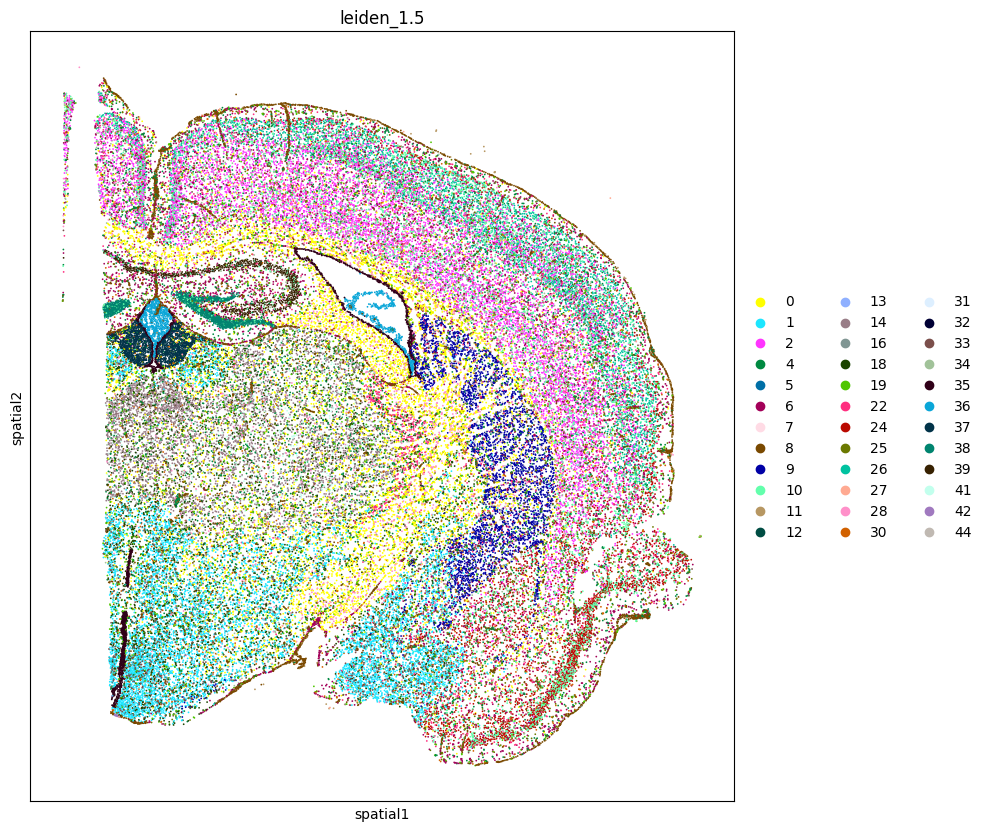

RB4350


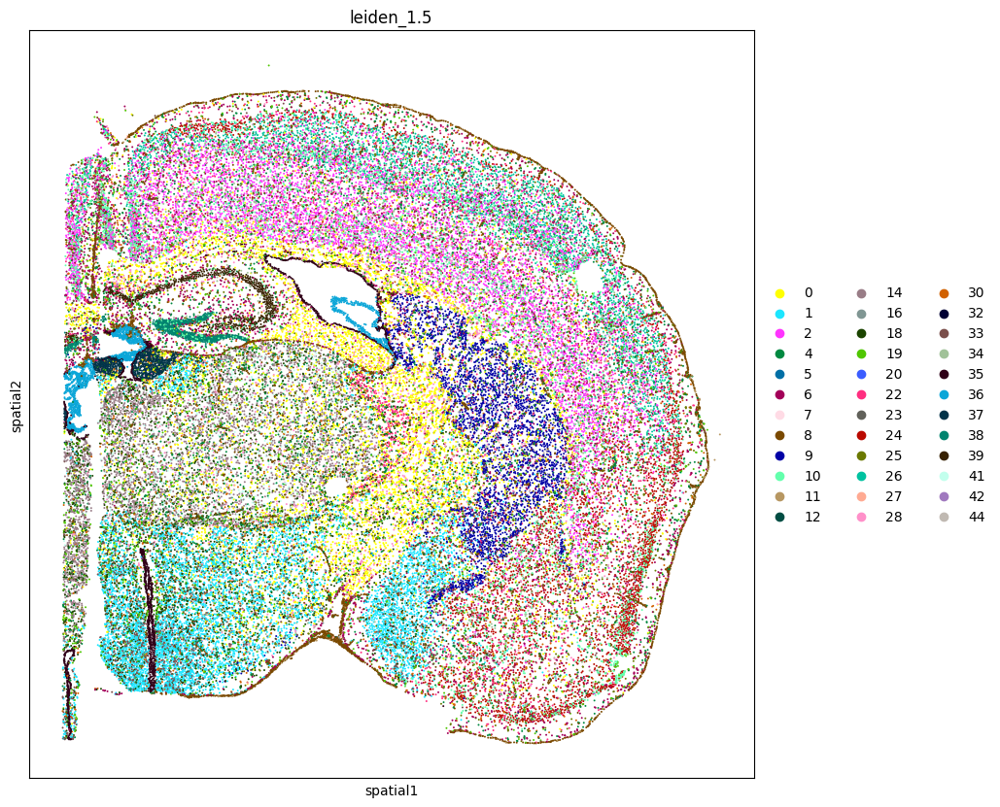

RB4401


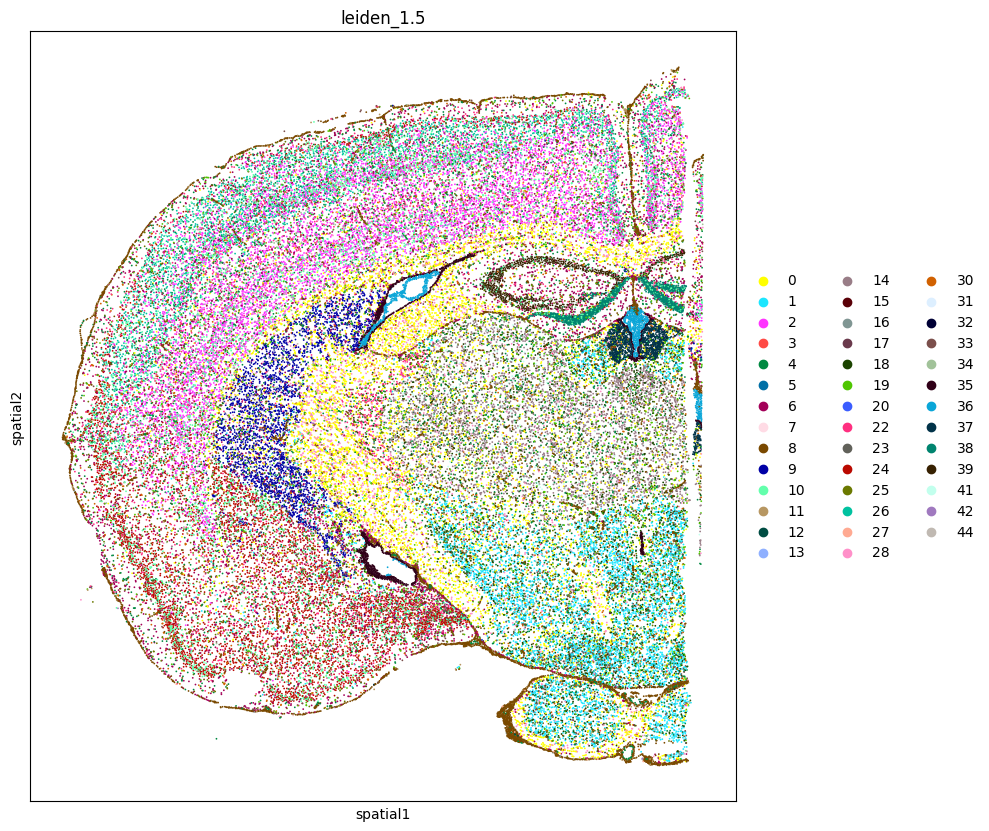

RB4403


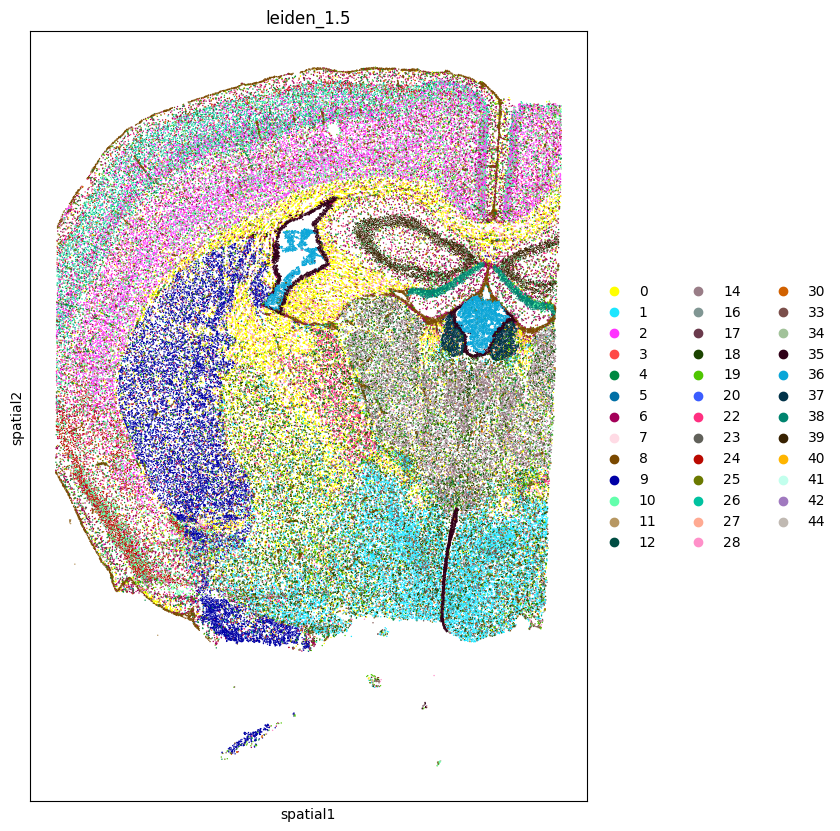

RB4405


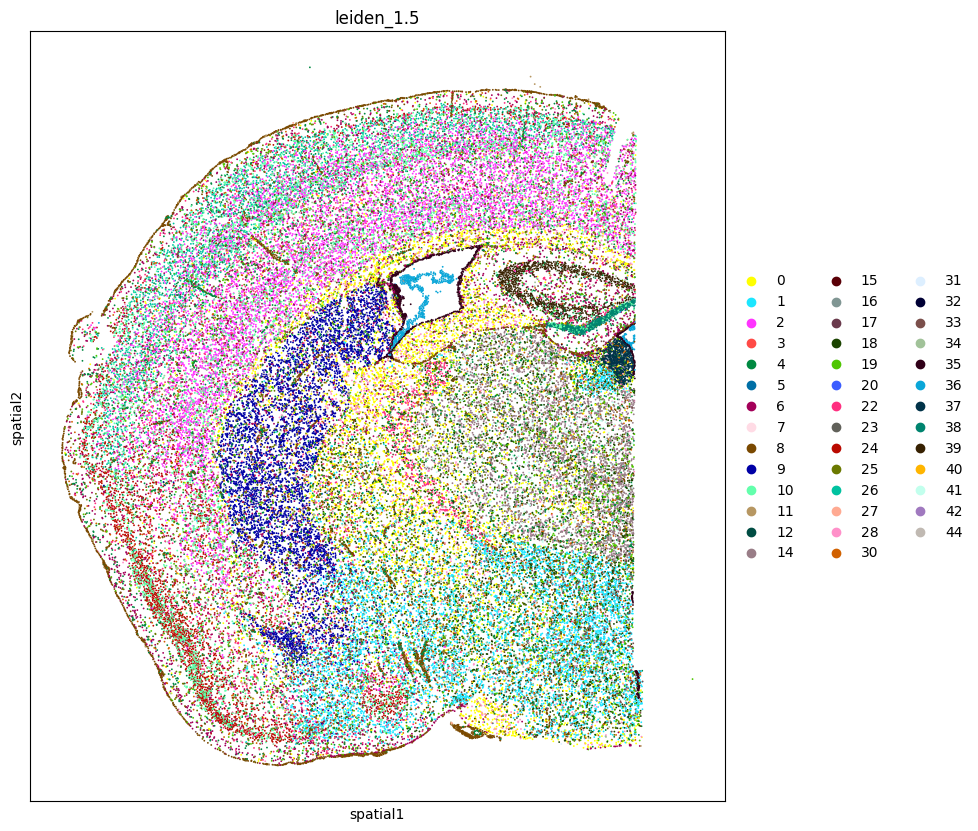

RB4498


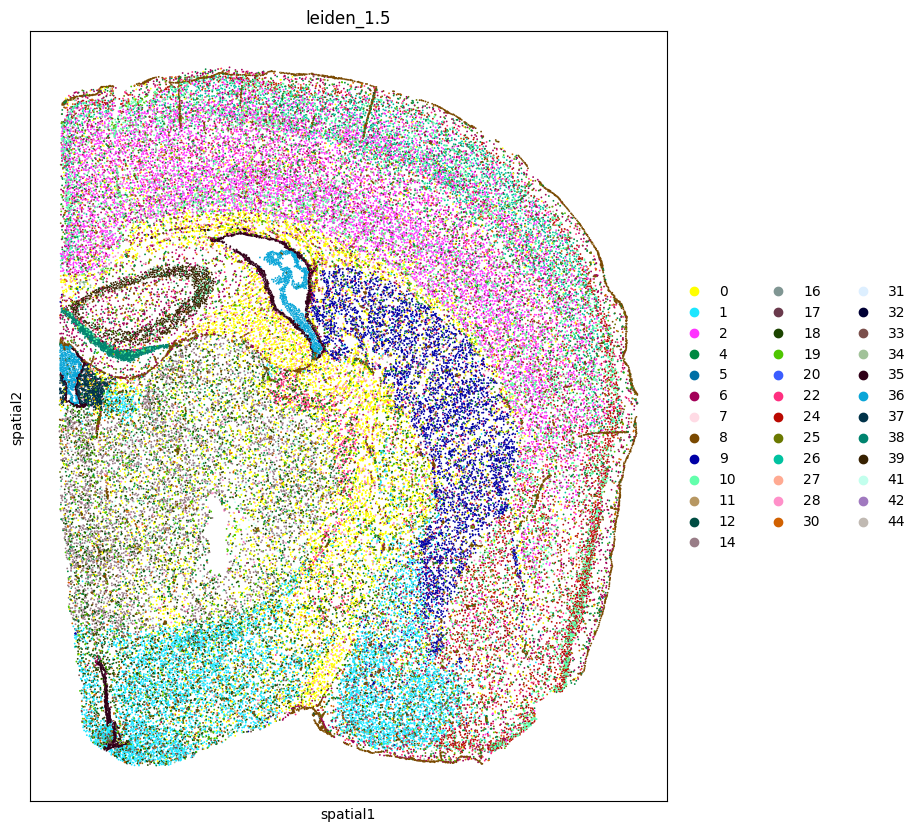

RB4620


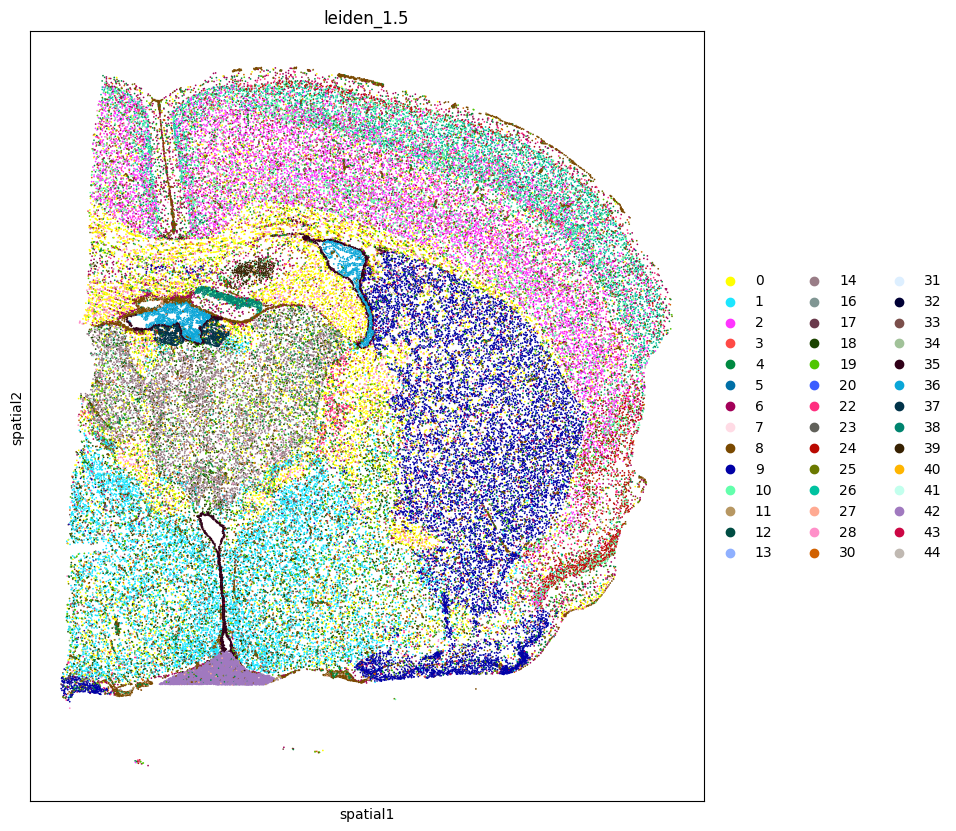

RB4627


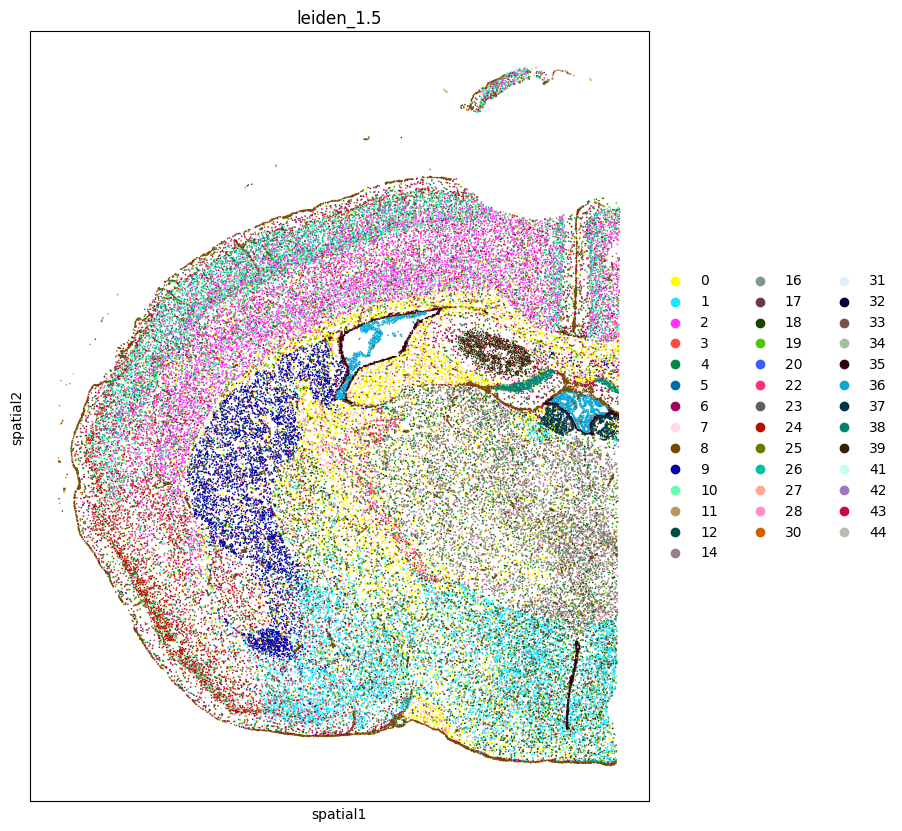

RB4630


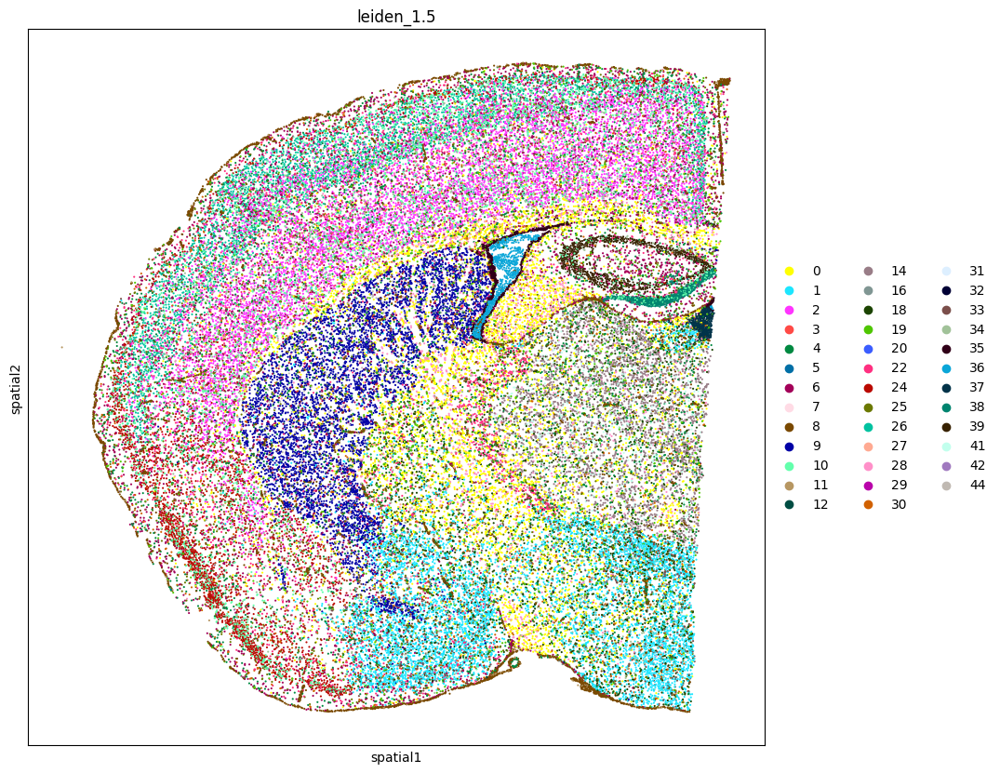

RB4653


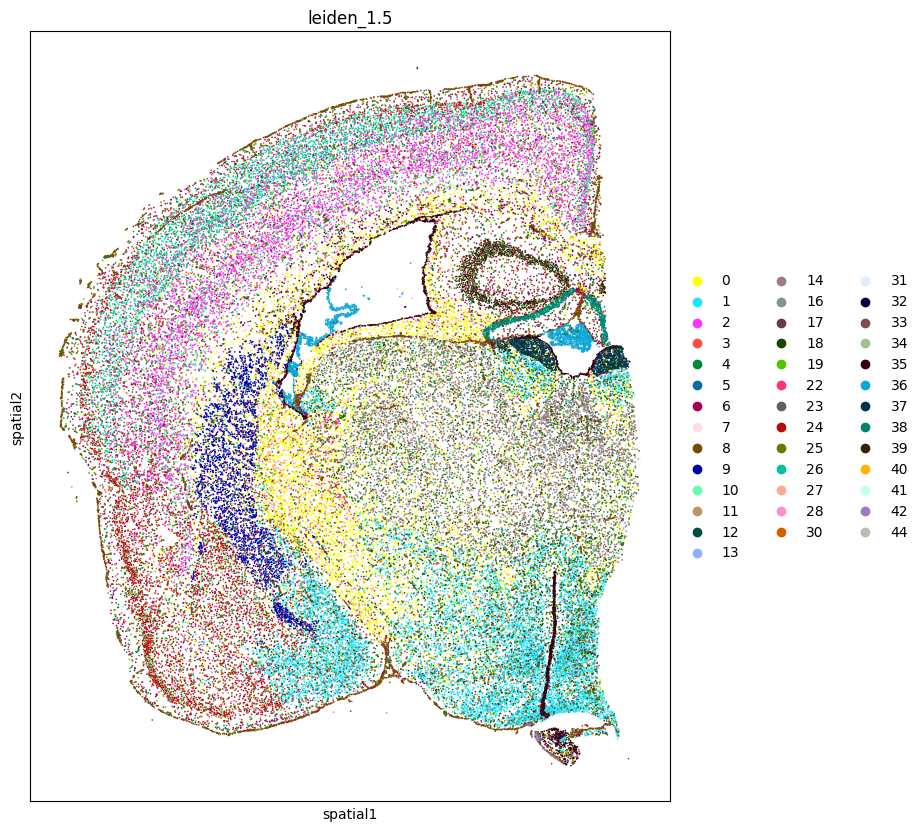

RB4658


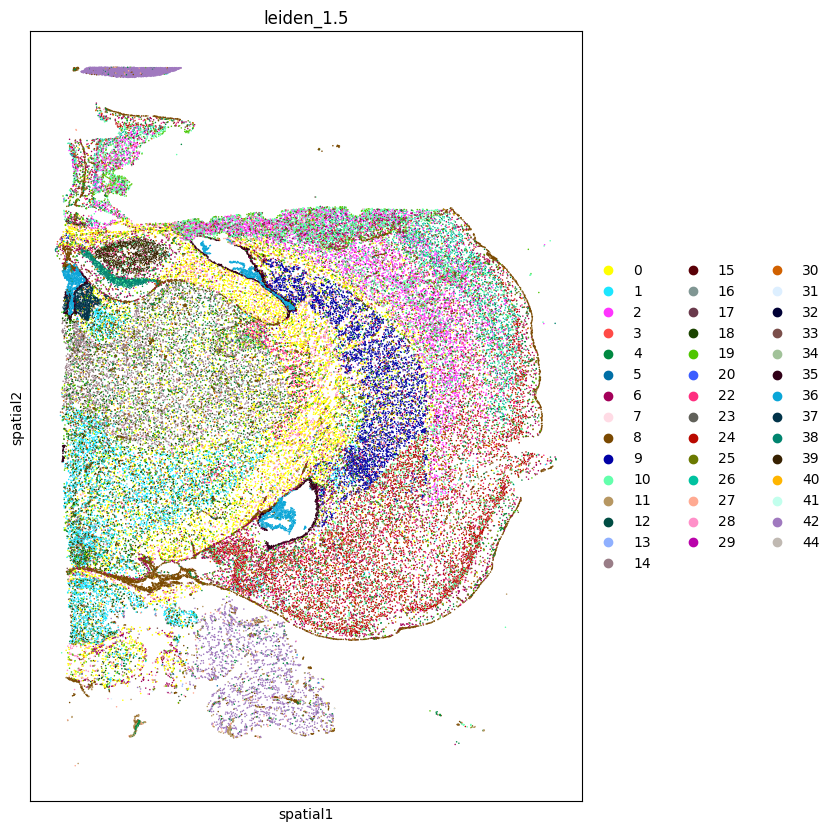

RB4676


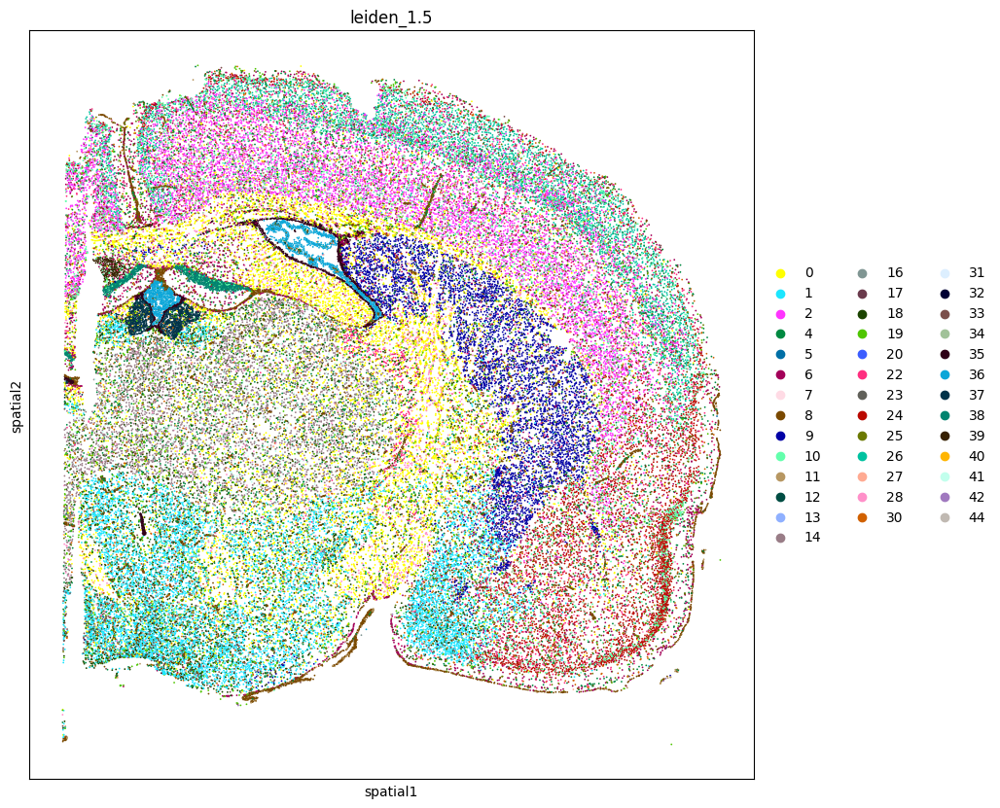

In [29]:
ad_mtDSB = ad[ad.obs.project == 'mtDSB']
for run in ad_mtDSB.obs['sample_extracted'].unique():
    print(run)
    ad_int = ad_mtDSB[ad_mtDSB.obs['sample_extracted'] == run]
    with plt.rc_context({'figure.figsize': (20, 10)}):
        sc.pl.spatial(ad_int, spot_size=15, color = 'leiden_1.5')
    plt.show()
    

S1-B1


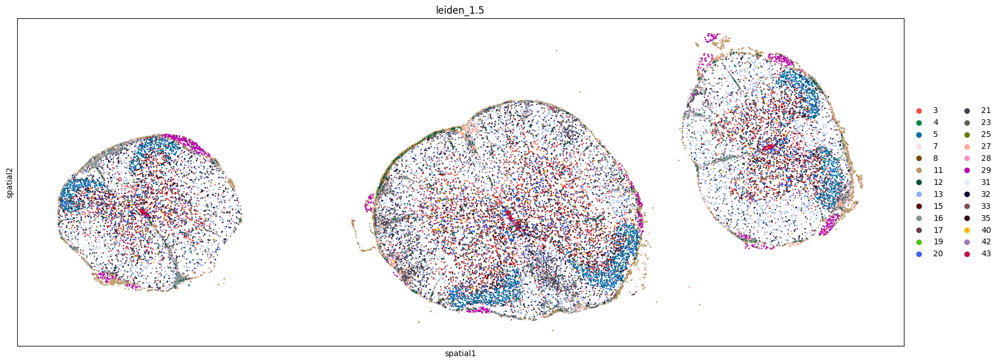

S1-B2


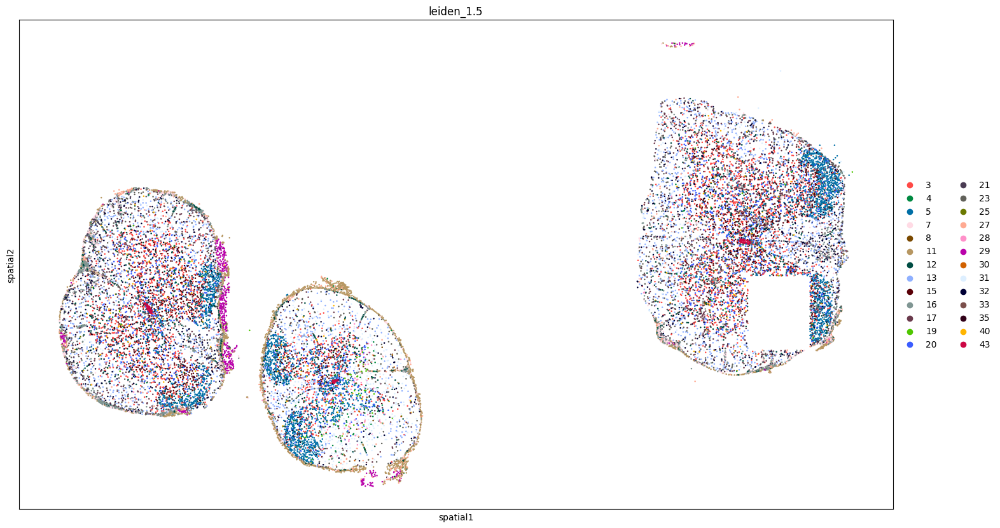

S1-B3


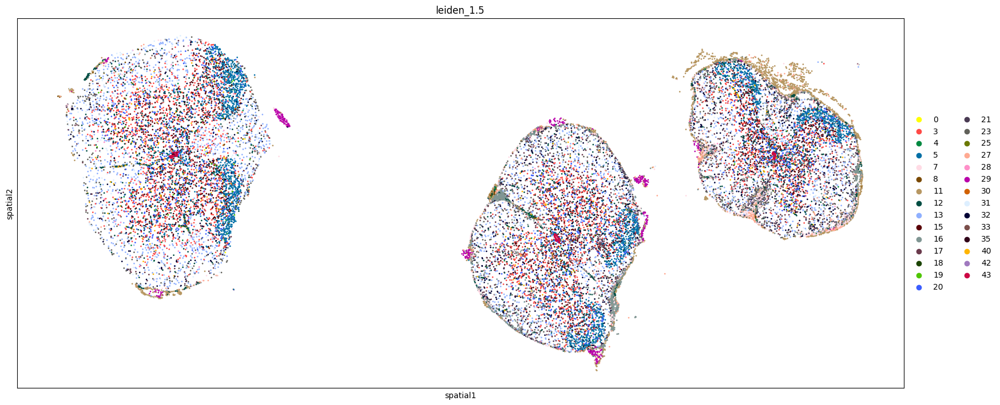

S1-T1


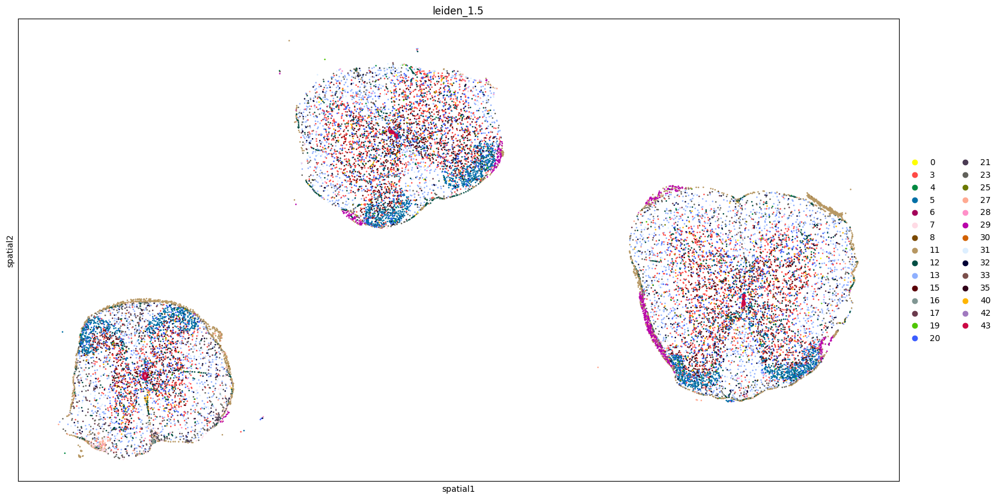

S1-T2


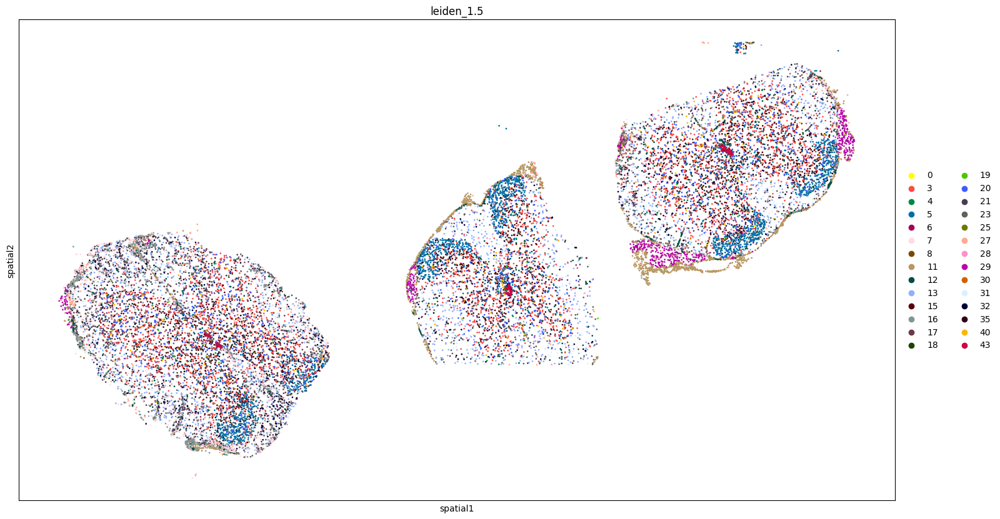

S1-T3


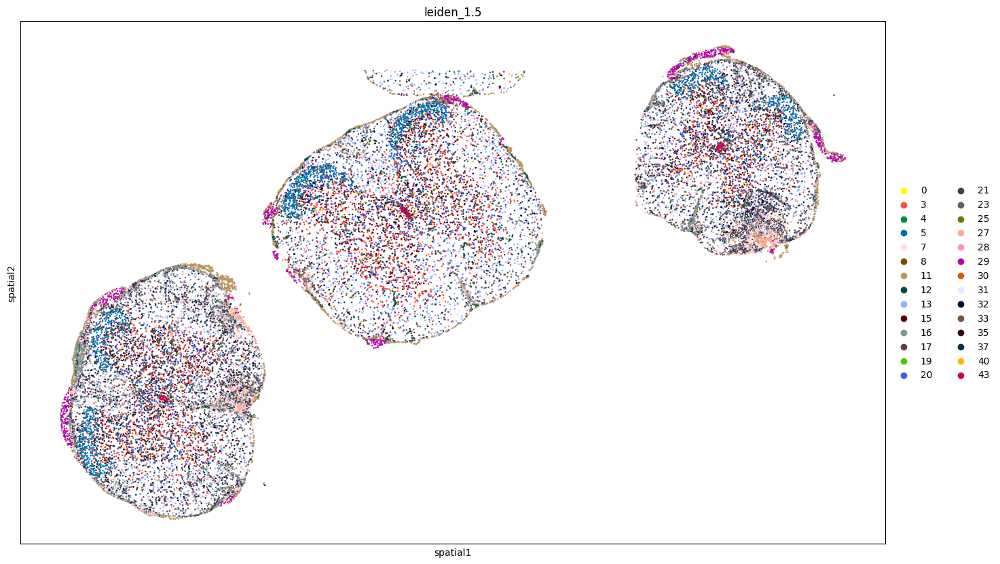

S2-B1


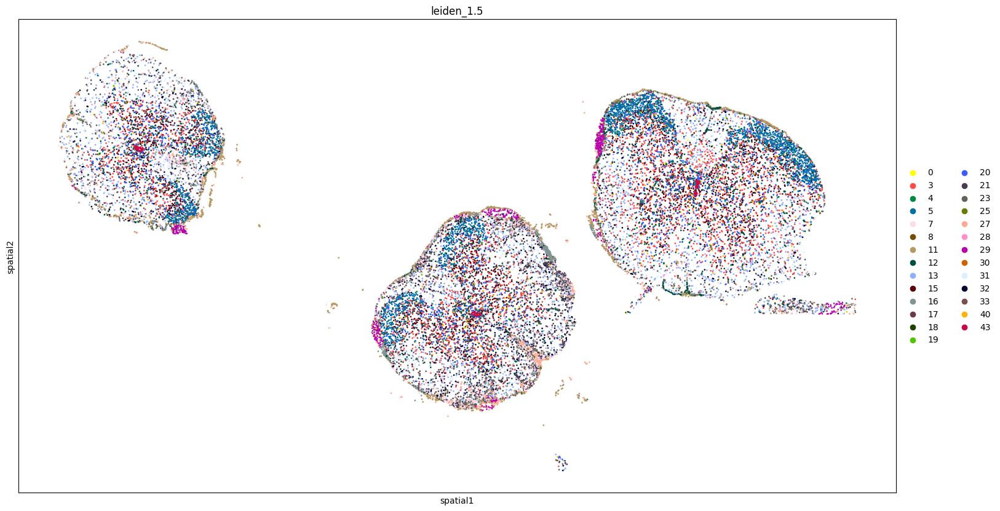

S2-B2


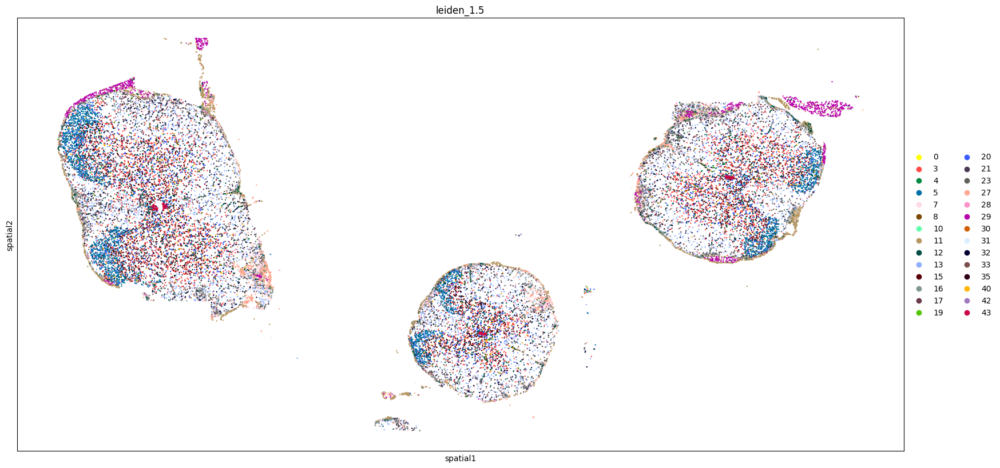

S4-B1


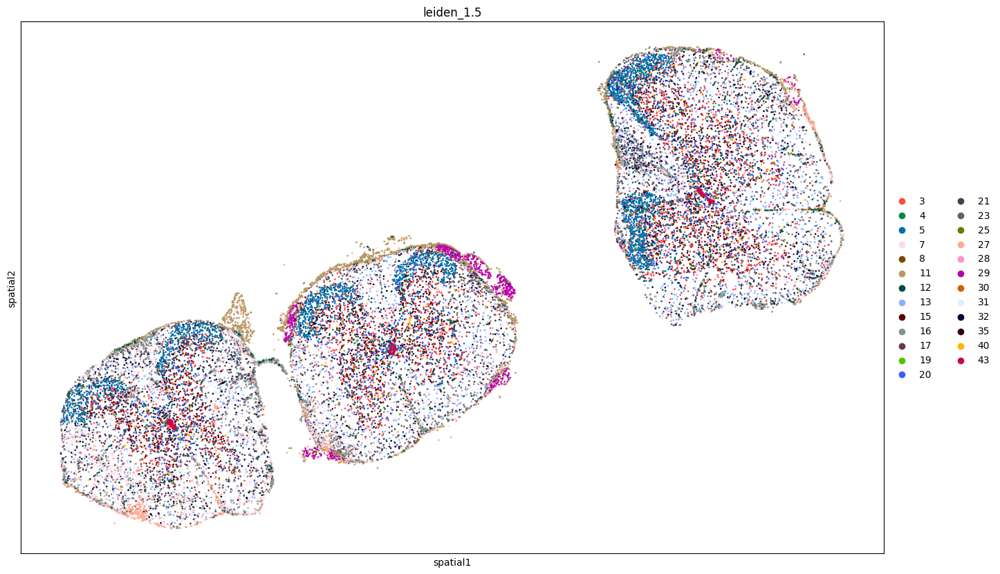

S4-B2


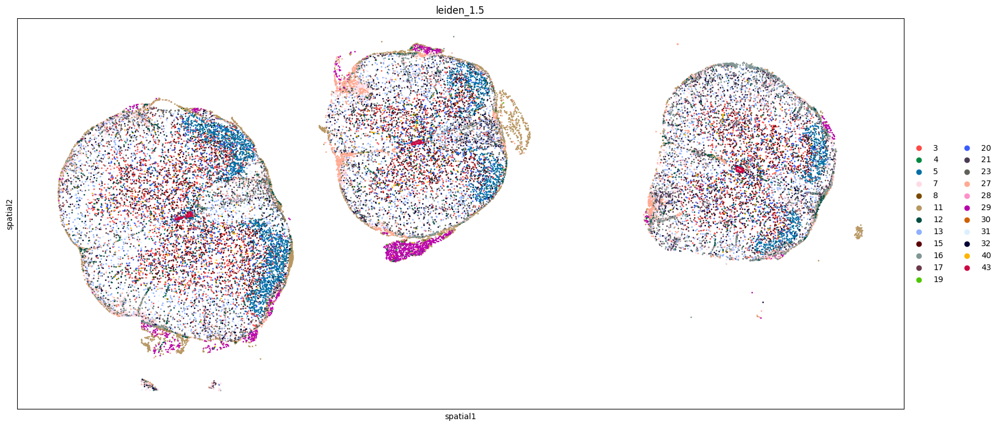

S4-B3


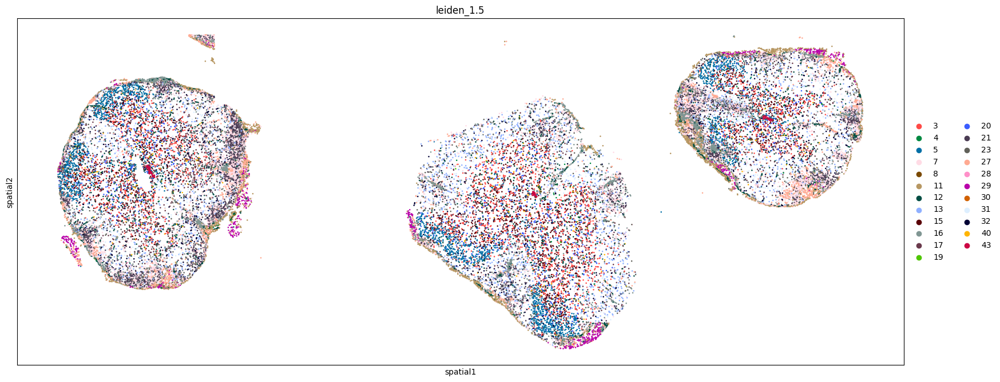

S4-T1


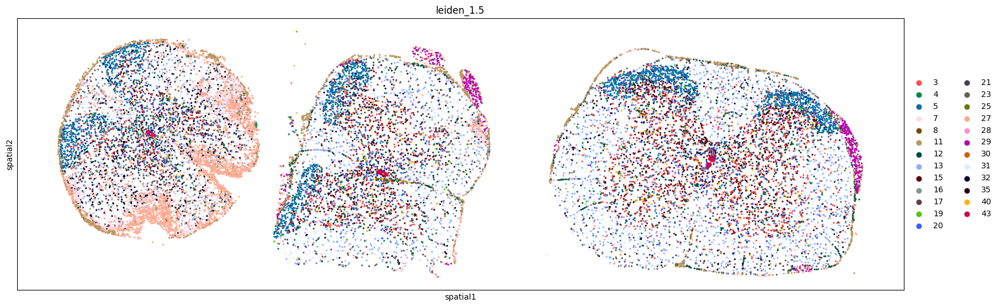

S4-T2


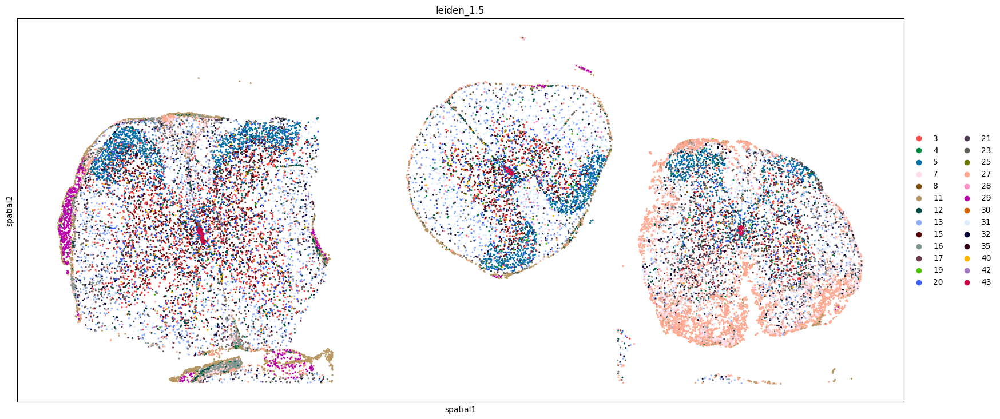

S4-T3


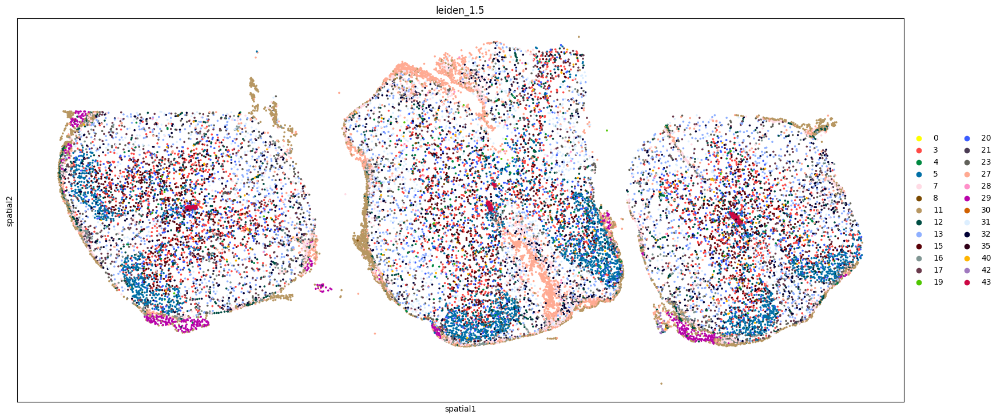

S3-B1


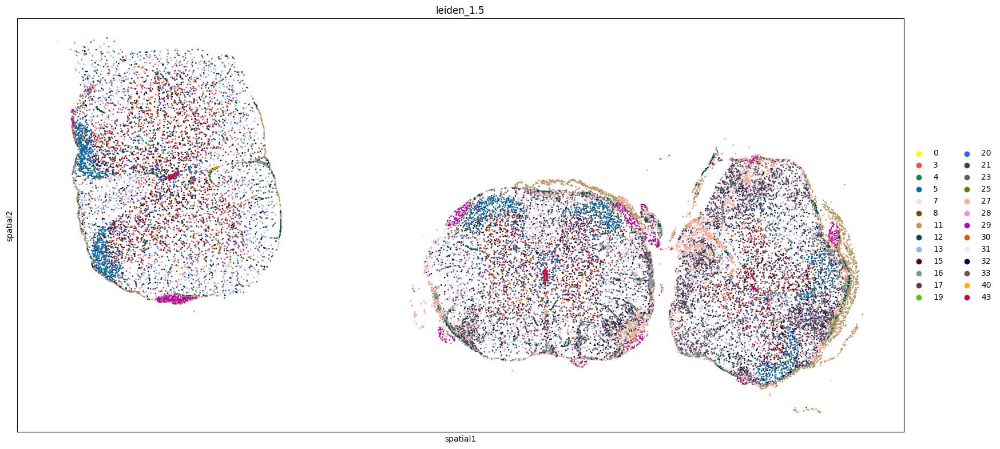

S3-B2


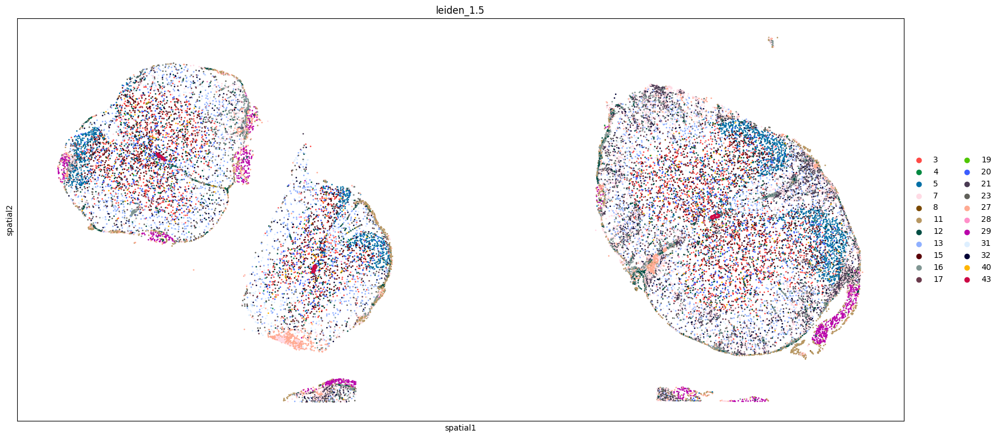

S3-B3


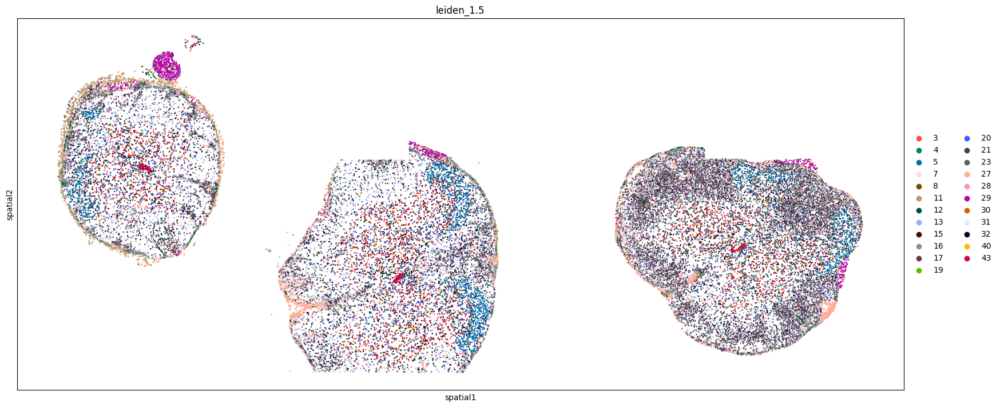

In [30]:
ad_RR = ad[ad.obs.project == 'RREAE']
for run in ad_RR.obs['sample_extracted'].unique():
    print(run)
    ad_int = ad_RR[ad_RR.obs['sample_extracted'] == run]
    with plt.rc_context({'figure.figsize': (20, 10)}):
        sc.pl.spatial(ad_int, spot_size=15, color = 'leiden_1.5')
    plt.show()
    

G3_L3


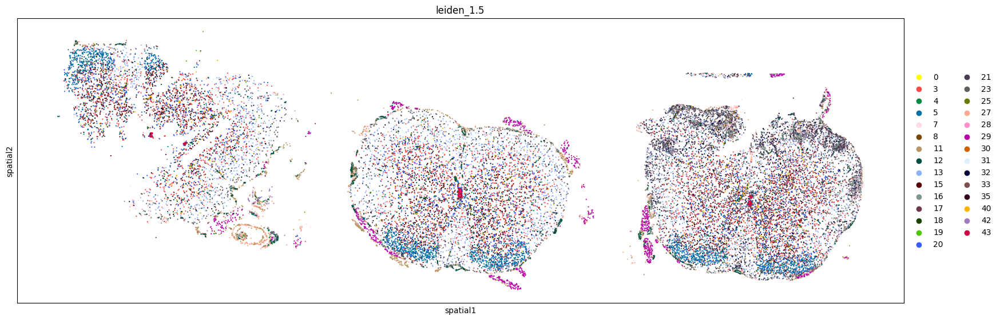

G5_L2


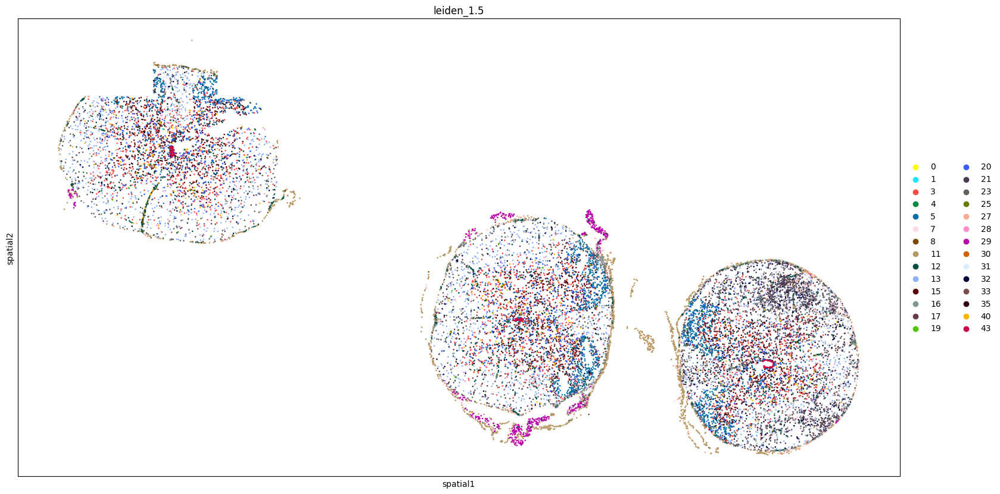

G3_L2


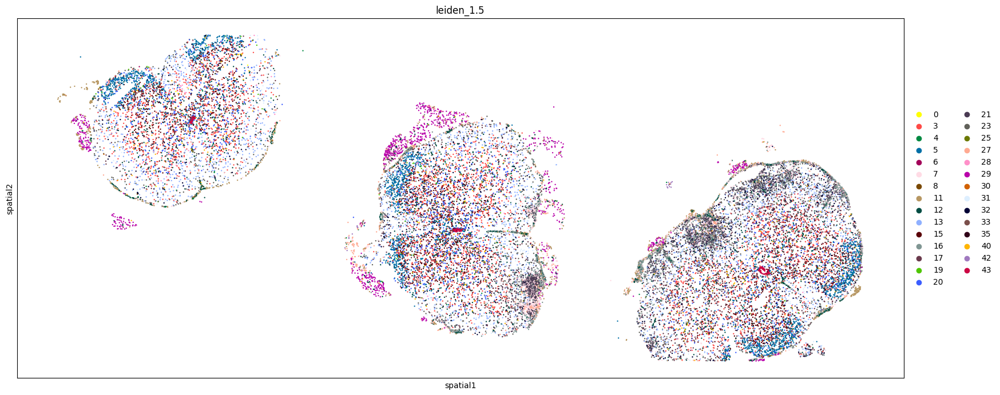

G5_L1


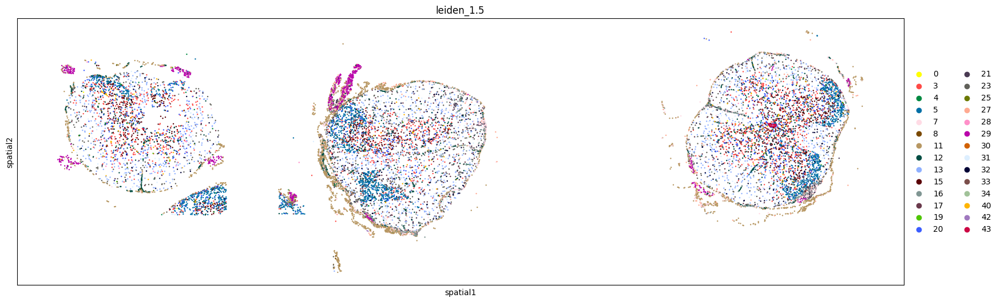

G3_L1


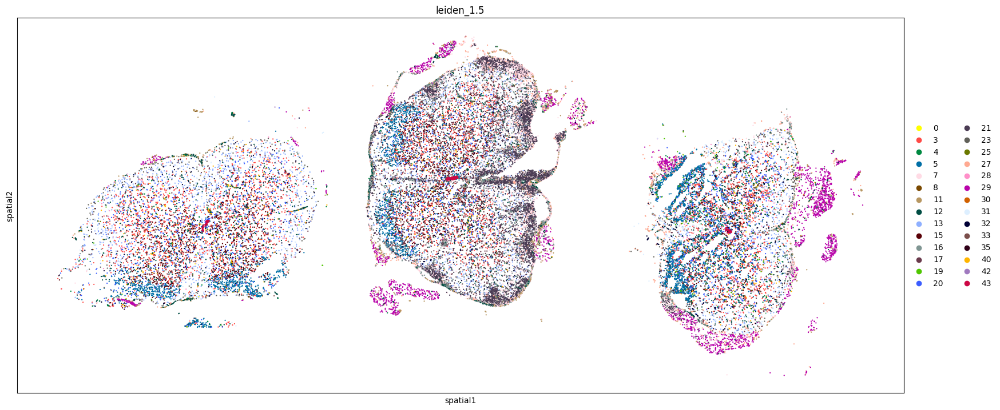

G5_L3


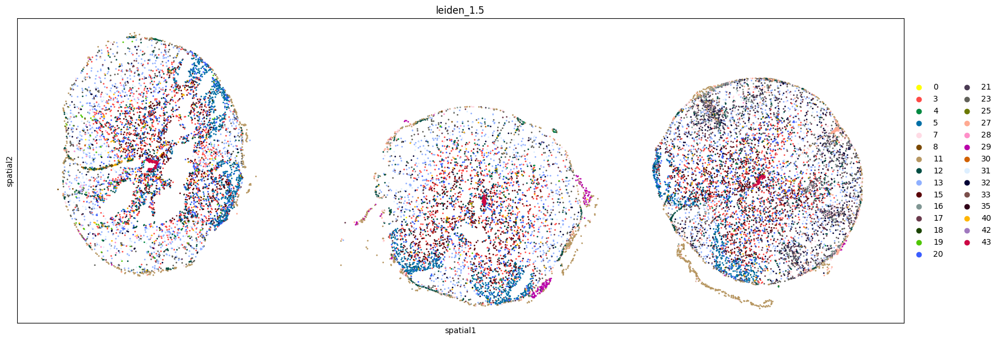

G4_L2


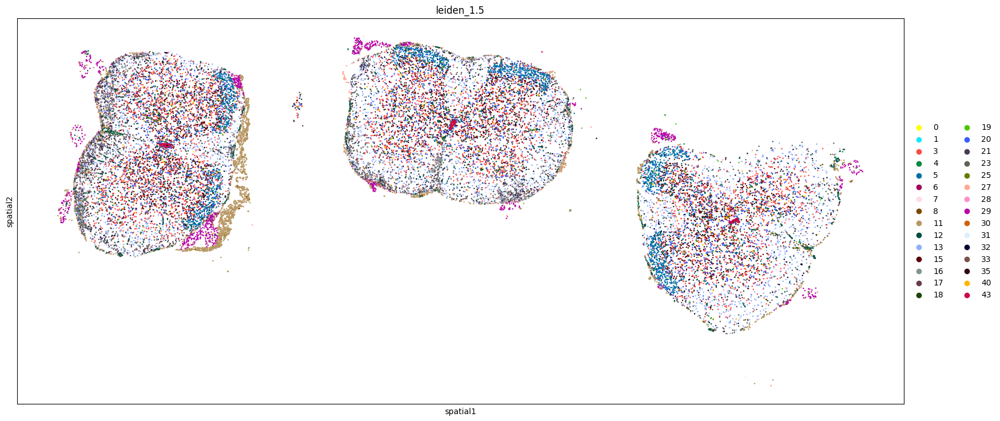

G6_L1


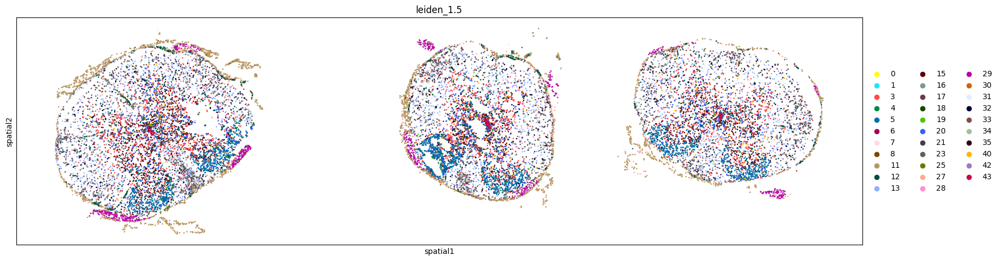

G4_L3


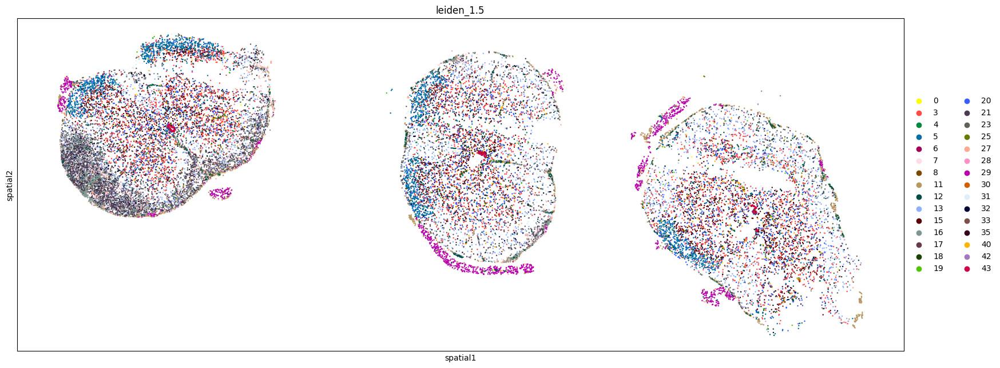

G6_L2


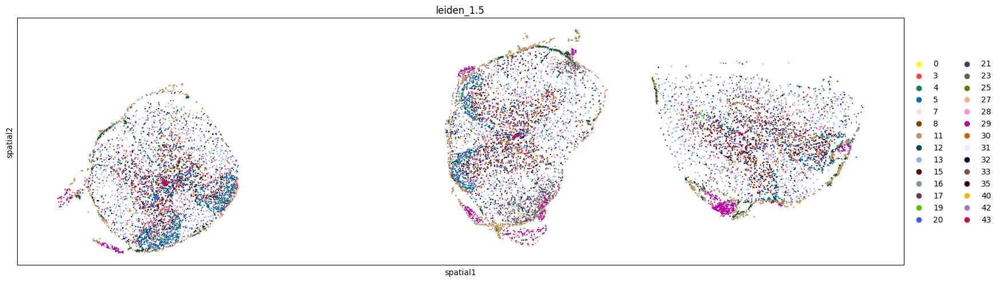

G6_L3


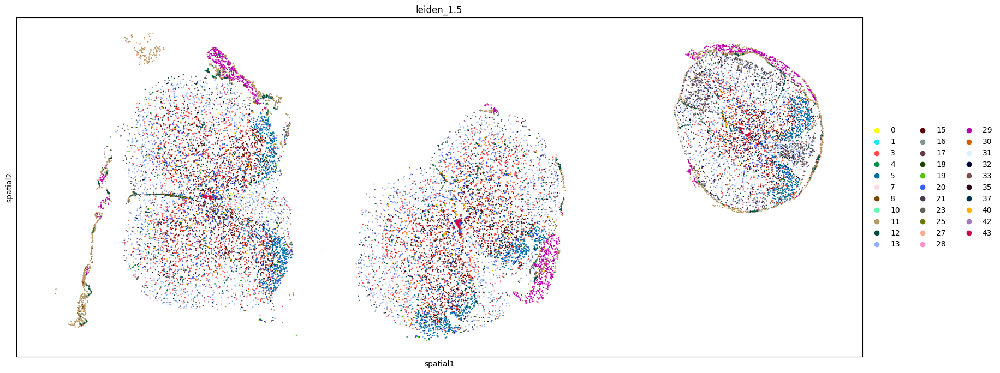

G4_L1


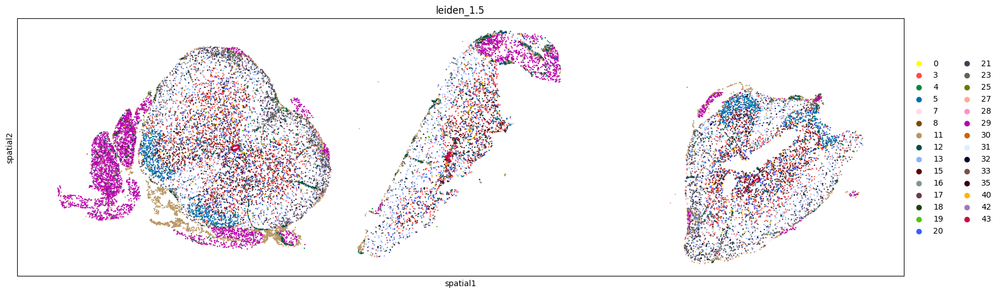

In [31]:
ad_chronic = ad[ad.obs.project == 'Chronic EAE']
for run in ad_chronic.obs['sample_extracted'].unique():
    print(run)
    ad_int = ad_chronic[ad_chronic.obs['sample_extracted'] == run]
    with plt.rc_context({'figure.figsize': (20, 10)}):
        sc.pl.spatial(ad_int, spot_size=15, color = 'leiden_1.5')
    plt.show()
    